In [2]:
!pip install shap

   ---------------------------------------- 0.0/547.2 kB ? eta -:--:--
   -- ------------------------------------- 41.0/547.2 kB 1.9 MB/s eta 0:00:01
   -------- ------------------------------- 112.6/547.2 kB 1.3 MB/s eta 0:00:01
   ---------------- ----------------------- 225.3/547.2 kB 1.7 MB/s eta 0:00:01
   ---------------------------- ----------- 389.1/547.2 kB 2.2 MB/s eta 0:00:01
   -------------------------------- ------- 450.6/547.2 kB 2.0 MB/s eta 0:00:01
   ---------------------------------------  542.7/547.2 kB 1.9 MB/s eta 0:00:01
   ---------------------------------------- 547.2/547.2 kB 1.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   - -------------------------------------- 0.1/2.7 MB 4.1 MB/s eta 0:00:01
   -- ------------------------------------- 0.2/2.7 MB 3.1 MB/s eta 0:00:01
   ---- ----------------------------------- 0.3/2.7 MB 3.0 MB/s eta 0:00:01
   ---- ----------------------------------- 0.3/2.7 MB 2.0 MB/s eta 0:00:


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import shap
import joblib
import matplotlib.pyplot as plt
import cv2
import os


In [15]:
MODEL_DIR = r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\models"
RESULTS_DIR = r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\notebooks\results"

# Load final optimized Swin-S model
model = joblib.load(f"{MODEL_DIR}/xgb_mobilevit_swinS_optuna.pkl")

# Load test data
X_test = np.load(f"{RESULTS_DIR}/X_test_swinS.npy")
y_test = np.load(f"{RESULTS_DIR}/y_test_swinS.npy")

print("Model & data loaded ")
print("Test shape:", X_test.shape)

Model & data loaded 
Test shape: (1388, 1408)


In [17]:
explainer = shap.TreeExplainer(model)

# Use subset for faster computation
X_sample = X_test[:200]

shap_values = explainer(X_sample)

print("SHAP computed ")
print("SHAP shape:", shap_values.values.shape)

SHAP computed 
SHAP shape: (200, 1408)


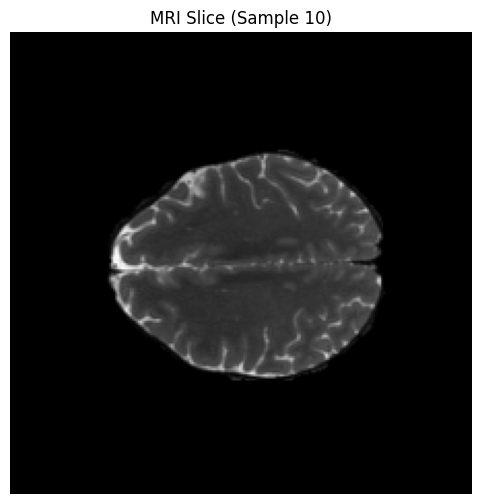

In [25]:
IMG_DIR = r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\raw\processed\images"

img_name = sorted(os.listdir(IMG_DIR))[sample_index]
img_path = os.path.join(IMG_DIR, img_name)

import cv2

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
img = cv2.resize(img, (224, 224))

plt.figure(figsize=(6,6))
plt.imshow(img, cmap='gray')
plt.title(f"MRI Slice (Sample {sample_index})")
plt.axis("off")
plt.show()

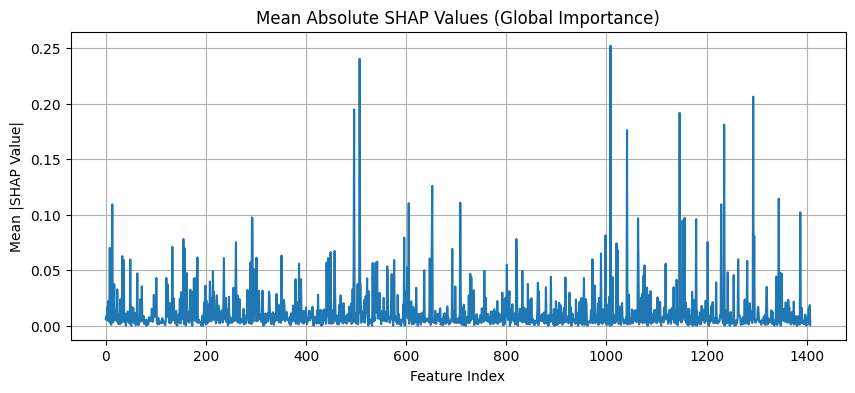

In [26]:
# Mean absolute SHAP values
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

plt.figure(figsize=(10,4))
plt.plot(mean_abs_shap)
plt.title("Mean Absolute SHAP Values (Global Importance)")
plt.xlabel("Feature Index")
plt.ylabel("Mean |SHAP Value|")
plt.grid(True)
plt.show()

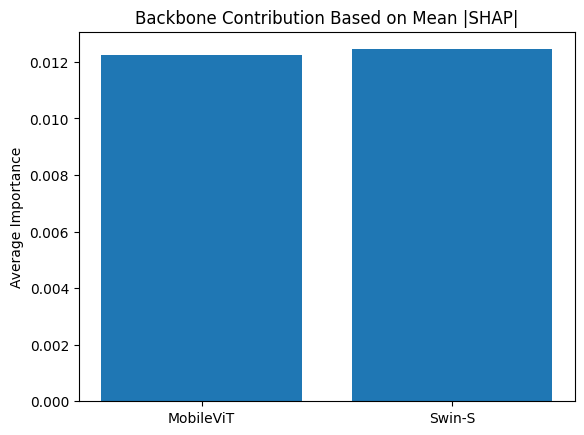

MobileViT Contribution: 0.012251472
Swin-S Contribution: 0.012444358


In [27]:
mobilevit_shap = np.abs(shap_values.values[:, :384]).mean()
swin_shap = np.abs(shap_values.values[:, 384:]).mean()

plt.bar(["MobileViT", "Swin-S"], [mobilevit_shap, swin_shap])
plt.title("Backbone Contribution Based on Mean |SHAP|")
plt.ylabel("Average Importance")
plt.show()

print("MobileViT Contribution:", mobilevit_shap)
print("Swin-S Contribution:", swin_shap)

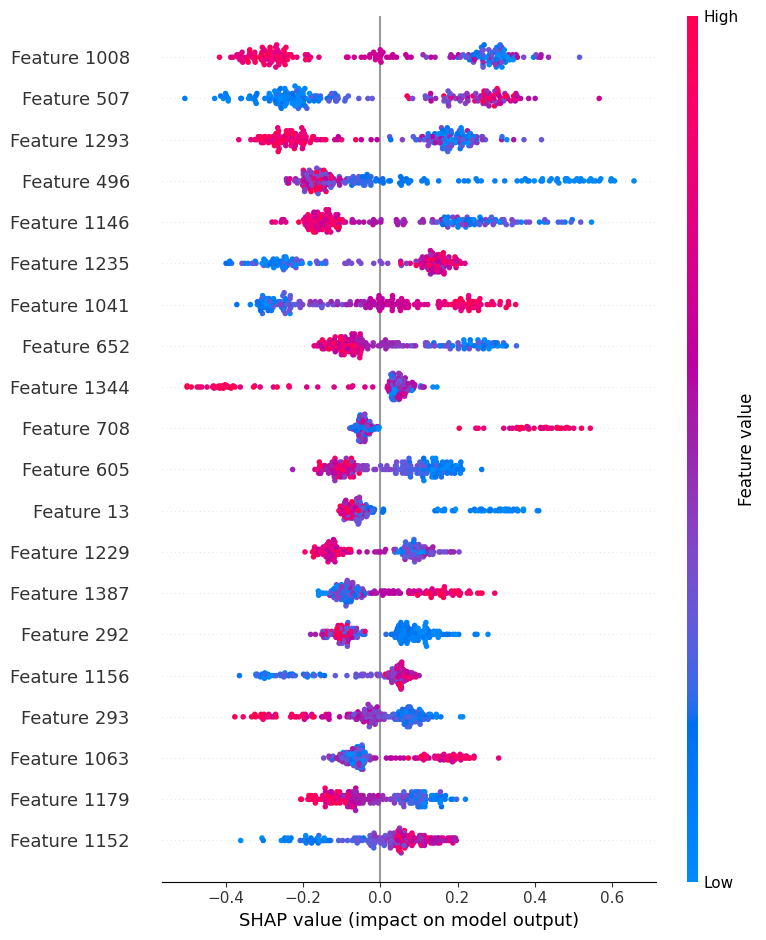

In [28]:
shap.summary_plot(shap_values, X_sample, max_display=20)

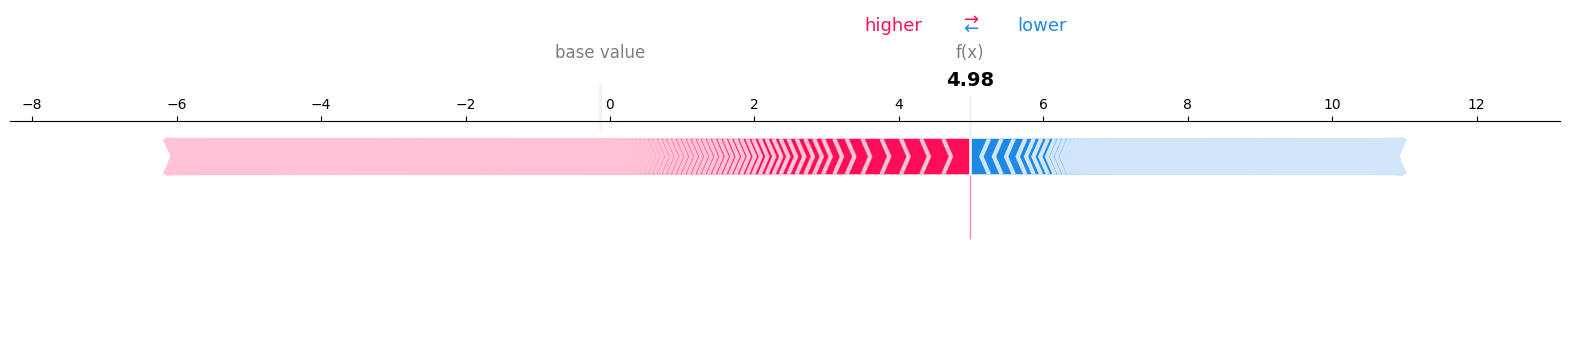

In [29]:
sample_index = 10

shap.force_plot(
    shap_values.base_values[sample_index],
    shap_values.values[sample_index],
    X_sample[sample_index],
    matplotlib=True
)

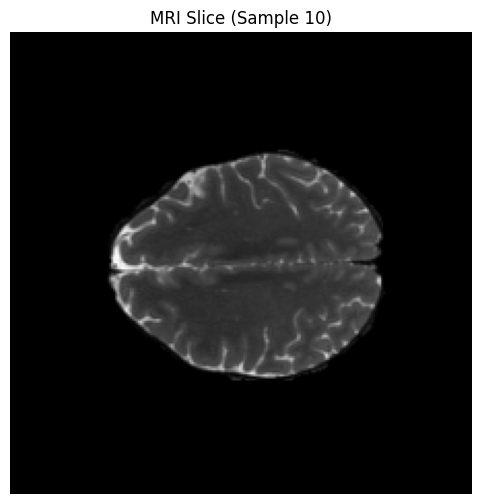

In [35]:
IMG_DIR = r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\raw\processed\images"

img_name = sorted(os.listdir(IMG_DIR))[sample_index]
img_path = os.path.join(IMG_DIR, img_name)

import cv2

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
img = cv2.resize(img, (224, 224))

plt.figure(figsize=(6,6))
plt.imshow(img, cmap='gray')
plt.title(f"MRI Slice (Sample {sample_index})")
plt.axis("off")
plt.show()

In [30]:
sample_index = 10

# Extract SHAP values (convert to numpy)
shap_sample = shap_values.values[sample_index]
shap_sample = np.abs(shap_sample)

# Normalize
shap_sample = shap_sample / np.max(shap_sample)

In [31]:
# Take first 1024 features (closest square)
shap_spatial = shap_sample[:1024]

# Reshape into square
shap_spatial = shap_spatial.reshape(32, 32)

# Resize to match image
shap_spatial = cv2.resize(shap_spatial, (224, 224))

In [32]:
heatmap = cv2.applyColorMap(
    (shap_spatial * 255).astype(np.uint8),
    cv2.COLORMAP_JET
)

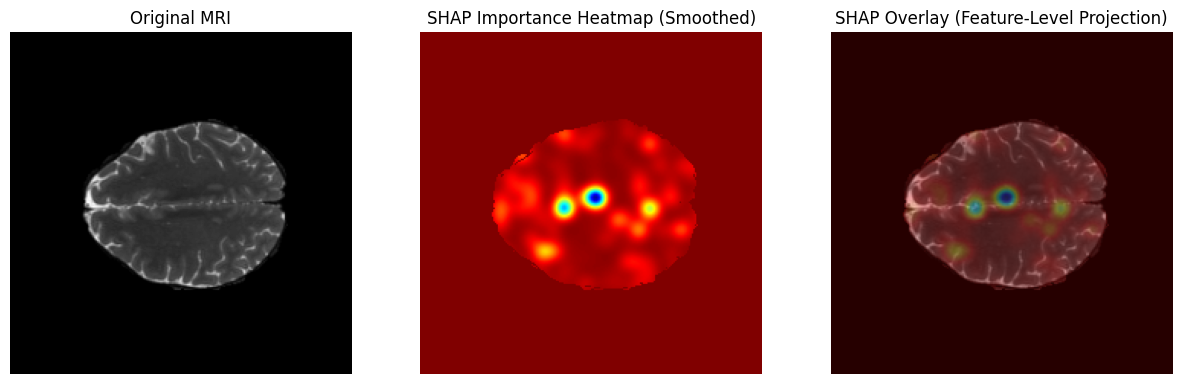

In [34]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

sample_index = 10

# Extract SHAP values
shap_sample = np.abs(shap_values.values[sample_index])

# Normalize
shap_sample = shap_sample / np.max(shap_sample)

# Take first 1024 features
shap_spatial = shap_sample[:1024].reshape(32, 32)

# Resize to image size
shap_spatial = cv2.resize(shap_spatial, (224, 224))

# Smooth (important!)
shap_spatial = cv2.GaussianBlur(shap_spatial, (21,21), 0)

# Normalize again
shap_spatial = shap_spatial / np.max(shap_spatial)

# Load MRI
IMG_DIR = r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\raw\processed\images"
img_name = sorted(os.listdir(IMG_DIR))[sample_index]
img_path = os.path.join(IMG_DIR, img_name)

img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
img = cv2.resize(img, (224, 224))

# Create brain mask (remove black background)
_, mask = cv2.threshold(img, 10, 1, cv2.THRESH_BINARY)
shap_spatial = shap_spatial * mask

# Create heatmap
heatmap = cv2.applyColorMap(
    (shap_spatial * 255).astype(np.uint8),
    cv2.COLORMAP_JET
)

# Overlay
img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

overlay = cv2.addWeighted(
    img_color,
    0.7,
    heatmap,
    0.3,
    0
)

# Plot
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(heatmap)
plt.title("SHAP Importance Heatmap (Smoothed)")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(overlay)
plt.title("SHAP Overlay (Feature-Level Projection)")
plt.axis("off")

plt.show()

In [36]:
import numpy as np

# Find indices
positive_indices = np.where(y_test == 1)[0]
negative_indices = np.where(y_test == 0)[0]

# Select one sample each
pos_index = positive_indices[0]
neg_index = negative_indices[0]

print("Positive sample index:", pos_index)
print("Negative sample index:", neg_index)

Positive sample index: 1
Negative sample index: 0


In [37]:
# Extract SHAP values
shap_pos = np.abs(shap_values.values[pos_index])
shap_neg = np.abs(shap_values.values[neg_index])

# Normalize
shap_pos = shap_pos / np.max(shap_pos)
shap_neg = shap_neg / np.max(shap_neg)

In [38]:
def create_shap_map(shap_sample):
    shap_spatial = shap_sample[:1024].reshape(32, 32)
    shap_spatial = cv2.resize(shap_spatial, (224, 224))
    shap_spatial = cv2.GaussianBlur(shap_spatial, (21,21), 0)
    shap_spatial = shap_spatial / np.max(shap_spatial)
    return shap_spatial

shap_map_pos = create_shap_map(shap_pos)
shap_map_neg = create_shap_map(shap_neg)

In [39]:
def load_image(index):
    img_name = sorted(os.listdir(IMG_DIR))[index]
    img_path = os.path.join(IMG_DIR, img_name)
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (224, 224))
    return img

img_pos = load_image(pos_index)
img_neg = load_image(neg_index)

In [40]:
def create_overlay(img, shap_map):
    _, mask = cv2.threshold(img, 10, 1, cv2.THRESH_BINARY)
    shap_map = shap_map * mask

    heatmap = cv2.applyColorMap(
        (shap_map * 255).astype(np.uint8),
        cv2.COLORMAP_JET
    )

    img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

    overlay = cv2.addWeighted(
        img_color,
        0.7,
        heatmap,
        0.3,
        0
    )

    return heatmap, overlay

In [41]:
heat_pos, overlay_pos = create_overlay(img_pos, shap_map_pos)
heat_neg, overlay_neg = create_overlay(img_neg, shap_map_neg)

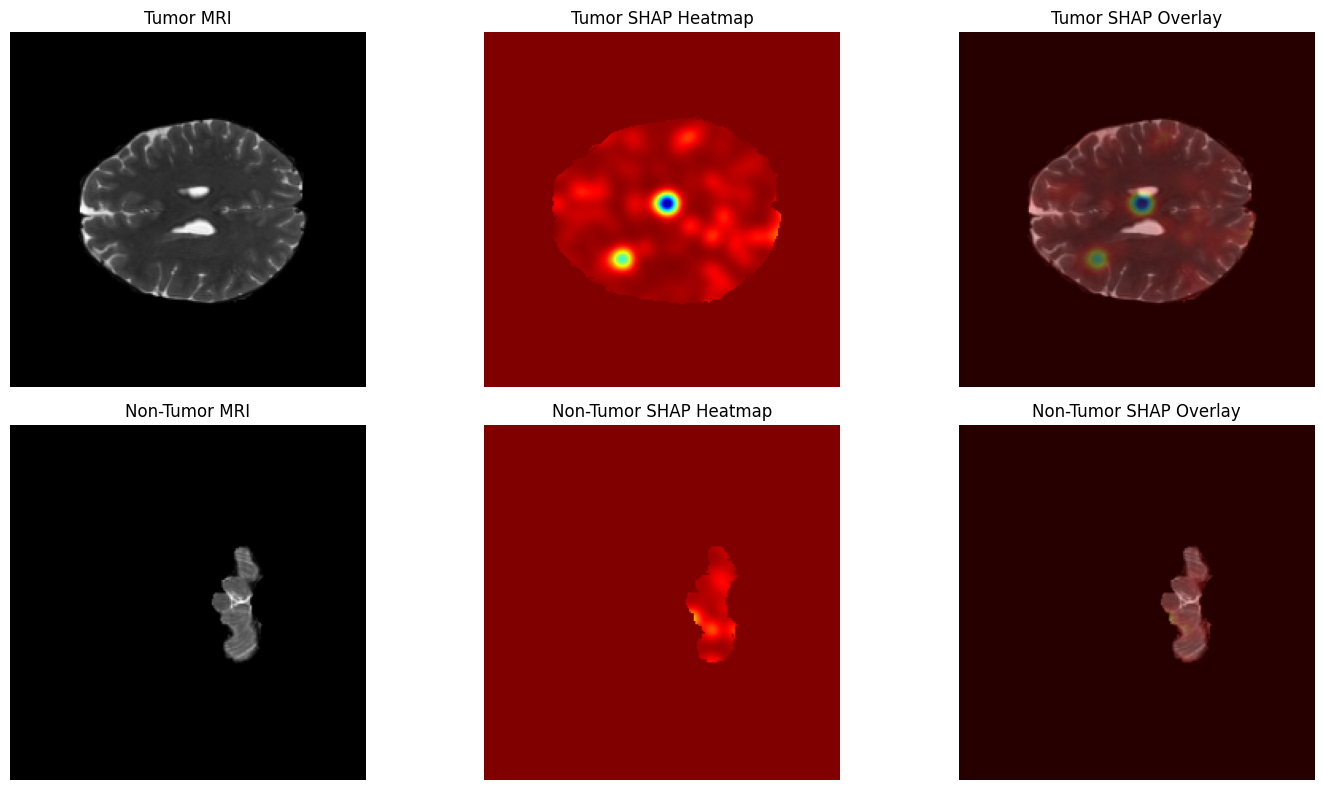

In [42]:
plt.figure(figsize=(15,8))

# Positive
plt.subplot(2,3,1)
plt.imshow(img_pos, cmap='gray')
plt.title("Tumor MRI")
plt.axis("off")

plt.subplot(2,3,2)
plt.imshow(heat_pos)
plt.title("Tumor SHAP Heatmap")
plt.axis("off")

plt.subplot(2,3,3)
plt.imshow(overlay_pos)
plt.title("Tumor SHAP Overlay")
plt.axis("off")

# Negative
plt.subplot(2,3,4)
plt.imshow(img_neg, cmap='gray')
plt.title("Non-Tumor MRI")
plt.axis("off")

plt.subplot(2,3,5)
plt.imshow(heat_neg)
plt.title("Non-Tumor SHAP Heatmap")
plt.axis("off")

plt.subplot(2,3,6)
plt.imshow(overlay_neg)
plt.title("Non-Tumor SHAP Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()